# Búsqueda de hiperparámetros con validación temporal — LightGBM

Semana 11 del plan de trabajo (proposal.md, sección 13). El notebook 03 dejó a LightGBM como mejor modelo (MAE = 4.07 min en mayo) con hiperparámetros fijados a mano. Aquí los buscamos de forma sistemática, siguiendo el plan de validación de la sección 10 del proposal:

- La búsqueda usa **solo entrenamiento (enero-abril)** con validación cruzada temporal (`TimeSeriesSplit`).
- **Mayo** se usa una sola vez al final, para comparar las configuraciones finalistas contra el modelo de la semana 10.
- **Junio** (test) no se toca.

La lógica reutilizable está en `src/tuning.py`. El notebook completo tarda cerca de 50 minutos en una laptop de 12 núcleos (la búsqueda de la sección 5 ocupa unos 34).

In [1]:
import sys
sys.path.append('..')

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb

from src.data import cargar_todo, split_temporal, MESES
from src.features import construir_preprocesador, preparar_xy
from src import tuning

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

import src.features as features
features.RUTA_ZONAS = Path('../data/Taxi_Zone_Lookup.csv')
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

## 1. Carga de los 6 meses y split temporal
Mismo muestreo que los notebooks 02 y 03 (`SAMPLE_FRAC = 0.20`, `SEED = 42`) para que las métricas sean comparables.

In [2]:
SAMPLE_FRAC = 0.20

df = cargar_todo(meses=MESES, sample_frac=SAMPLE_FRAC, seed=SEED)
train, val, test = split_temporal(df)
del df, test
print(f"Train (ene-abr): {len(train):,}  <- búsqueda de hiperparámetros")
print(f"Val   (mayo):    {len(val):,}  <- solo comparación final")
print("Test  (junio):   no se usa en este notebook")

Train (ene-abr): 2,872,441  <- búsqueda de hiperparámetros
Val   (mayo):    855,412  <- solo comparación final
Test  (junio):   no se usa en este notebook


## 2. Folds de validación cruzada temporal

Ordenamos los viajes de entrenamiento por fecha de recojo y aplicamos `TimeSeriesSplit(n_splits=3)`: cada fold entrena con el pasado y valida con el bloque de viajes inmediatamente posterior, igual que el split global (entrenar con enero-abril, predecir mayo).

**Control de leakage dentro de la validación cruzada.** El preprocesador de `src/features.py` aprende del target y de `trip_distance` (distancia histórica por par de zonas y TargetEncoder de zonas). Por eso se **reajusta en cada fold usando solo la parte de entrenamiento de ese fold**; reutilizar el preprocesador ajustado con enero-abril filtraría información del bloque de validación. Como el preprocesador no depende de los hiperparámetros del modelo, se ajusta una vez por fold y se reutiliza en todas las configuraciones.

In [3]:
t0 = time.time()
folds = tuning.preparar_folds(train, n_splits=3)
print(f"Folds preparados en {time.time() - t0:.0f} s | {len(folds[0]['nombres'])} features")
tuning.resumen_folds(folds)

Folds preparados en 11 s | 41 features


,fold,filas_train,train,filas_val,val
0,1,718111,01-Jan a 03-Feb,718110,03-Feb a 04-Mar
1,2,1436221,01-Jan a 04-Mar,718110,04-Mar a 02-Apr
2,3,2154331,01-Jan a 02-Apr,718110,02-Apr a 30-Apr


## 3. Cómo se evalúa cada configuración

Para cada configuración y cada fold (`tuning.evaluar_config`):

- El modelo entrena sobre `log1p(duración)`, como en el notebook 03, y la predicción se devuelve a minutos con `expm1`.
- El **número de árboles no se busca**: se entrena con early stopping (paciencia de 30 iteraciones) midiendo el MAE en minutos sobre el bloque de validación del fold. El número final de árboles es el promedio de los tres folds.
- El puntaje de la configuración es el **MAE promedio de los 3 folds** (métrica principal del proposal). El RMSLE se reporta como métrica secundaria.

El early stopping usa el mismo bloque con el que se puntúa el fold, así que el MAE de validación cruzada es ligeramente optimista. Afecta a todas las configuraciones por igual, y la comparación final se hace sobre mayo, que no participa en la búsqueda.

Durante la búsqueda el learning rate queda fijo en 0.2 para que cada configuración entrene rápido. Con early stopping, el learning rate solo intercambia velocidad por número de árboles, así que se baja al final (sección 6).

In [4]:
LR_BUSQUEDA = 0.2
PACIENCIA = 30

referencia = {**tuning.PARAMS_SEMANA_10, 'learning_rate': LR_BUSQUEDA}

## 4. ¿Conviene quitar `pickup_month`?

Punto pendiente del notebook 03: con split temporal, el mes de validación nunca aparece en entrenamiento, así que los árboles tratan todo viaje futuro como si fuera del último mes visto. Lo medimos con la configuración de la semana 10, con y sin la feature. La validación cruzada temporal reproduce el problema, porque en cada fold el bloque de validación es posterior al de entrenamiento.

In [5]:
r_con = tuning.evaluar_config(referencia, folds, paciencia=PACIENCIA)
r_sin = tuning.evaluar_config(referencia, folds, excluir=('num__pickup_month',), paciencia=PACIENCIA)

ablacion = pd.DataFrame([
    {'features': 'con pickup_month', **r_con},
    {'features': 'sin pickup_month', **r_sin},
])[['features', 'cv_MAE', 'cv_MAE_std', 'cv_RMSLE', 'MAE_por_fold', 'arboles_por_fold']]

# Se quita si no empeora el MAE de validación cruzada: es una feature que no puede generalizar
EXCLUIR = ('num__pickup_month',) if r_sin['cv_MAE'] <= r_con['cv_MAE'] else ()
r_ref = r_sin if EXCLUIR else r_con
print(f"Features excluidas en adelante: {list(EXCLUIR)}")
ablacion

Features excluidas en adelante: []


,features,cv_MAE,cv_MAE_std,cv_RMSLE,MAE_por_fold,arboles_por_fold
0,con pickup_month,3.495251,0.086065,0.311331,"[3.3913, 3.4924, 3.602]","[338, 563, 469]"
1,sin pickup_month,3.504338,0.106772,0.311293,"[3.3715, 3.5086, 3.6329]","[475, 535, 603]"


## 5. Búsqueda aleatoria

Espacio de búsqueda (`tuning.muestrear_configuraciones`), 20 configuraciones muestreadas con semilla fija:

| Hiperparámetro | Rango | Qué controla |
|---|---|---|
| `objective` | L2 o L1 sobre `log1p(duración)` | L2 apunta a la media en log (afín al RMSLE); L1 apunta a la mediana, que es lo que minimiza el MAE |
| `num_leaves` | 31 a 511 (log-uniforme) | Complejidad de cada árbol |
| `min_child_samples` | 20 a 500 (log-uniforme) | Mínimo de viajes por hoja |
| `subsample` | 0.6 a 1.0 | Fracción de filas por árbol |
| `colsample_bytree` | 0.5 a 1.0 | Fracción de features por árbol |
| `reg_alpha`, `reg_lambda` | 0.001 a 10 (log-uniforme) | Regularización L1 y L2 de las hojas |

Usamos búsqueda aleatoria en lugar de grilla porque con 7 hiperparámetros una grilla gastaría casi todo el presupuesto en combinaciones de los que menos importan.

In [6]:
N_CONFIGS = 20

configs = tuning.muestrear_configuraciones(N_CONFIGS, seed=SEED, learning_rate=LR_BUSQUEDA)
t0 = time.time()
busqueda = tuning.busqueda_aleatoria(configs, folds, excluir=EXCLUIR, paciencia=PACIENCIA)
print(f"\nBúsqueda completa en {(time.time() - t0) / 60:.1f} min")

[ 1/20] cv_MAE = 3.4876 | cv_RMSLE = 0.3101 | regression     hojas=106  árboles=[614, 734, 1069] | 159 s


[ 2/20] cv_MAE = 3.4715 | cv_RMSLE = 0.3104 | regression_l1  hojas=281  árboles=[234, 312, 365] | 112 s


[ 3/20] cv_MAE = 3.4957 | cv_RMSLE = 0.3109 | regression     hojas=107  árboles=[346, 671, 526] | 97 s


[ 4/20] cv_MAE = 3.4846 | cv_RMSLE = 0.3111 | regression_l1  hojas=259  árboles=[233, 308, 298] | 92 s


[ 5/20] cv_MAE = 3.5024 | cv_RMSLE = 0.3113 | regression     hojas=35   árboles=[542, 972, 1962] | 116 s


[ 6/20] cv_MAE = 3.5135 | cv_RMSLE = 0.3120 | regression     hojas=88   árboles=[351, 602, 422] | 75 s


... (10 outputs left out)

[17/20] cv_MAE = 3.4887 | cv_RMSLE = 0.3102 | regression     hojas=231  árboles=[188, 309, 418] | 102 s


[18/20] cv_MAE = 3.4978 | cv_RMSLE = 0.3121 | regression_l1  hojas=55   árboles=[525, 652, 758] | 104 s


[19/20] cv_MAE = 3.4919 | cv_RMSLE = 0.3112 | regression     hojas=104  árboles=[400, 594, 563] | 81 s


[20/20] cv_MAE = 3.5092 | cv_RMSLE = 0.3128 | regression_l1  hojas=35   árboles=[859, 969, 889] | 122 s

Búsqueda completa en 33.6 min


In [7]:
cols_tabla = ['config', 'objective', 'num_leaves', 'min_child_samples', 'subsample', 'colsample_bytree',
              'reg_alpha', 'reg_lambda', 'cv_MAE', 'cv_MAE_std', 'cv_RMSLE', 'arboles_por_fold', 'segundos']
print(f"Referencia (semana 10): cv_MAE = {r_ref['cv_MAE']:.4f} | cv_RMSLE = {r_ref['cv_RMSLE']:.4f}")
busqueda[cols_tabla].head(10)

Referencia (semana 10): cv_MAE = 3.4953 | cv_RMSLE = 0.3113


,config,objective,num_leaves,min_child_samples,subsample,colsample_bytree,reg_alpha,reg_lambda,cv_MAE,cv_MAE_std,cv_RMSLE,arboles_por_fold,segundos
0,1,regression_l1,281,30,0.780,0.685,5.0940,0.3762,3.471519,0.080536,0.310378,"[234, 312, 365]",111.5
1,8,regression_l1,200,194,0.912,0.729,0.1883,0.0036,3.478760,0.078588,0.311098,"[290, 553, 487]",119.8
2,3,regression_l1,259,63,0.988,0.947,1.2988,0.0060,3.484569,0.073807,0.311109,"[233, 308, 298]",91.5
3,11,regression_l1,339,42,0.623,0.641,0.0149,0.4443,3.485030,0.080425,0.311327,"[122, 218, 268]",86.2
4,12,regression,279,170,0.763,0.907,0.0047,0.0012,3.485337,0.077833,0.310189,"[123, 261, 271]",71.4
5,0,regression,106,317,0.879,0.547,7.9889,1.1080,3.487597,0.089383,0.310077,"[614, 734, 1069]",158.7
6,16,regression,231,85,0.709,0.548,4.0776,0.0665,3.488738,0.081387,0.310227,"[188, 309, 418]",101.9
7,10,regression_l1,149,53,0.612,0.718,0.0072,0.0431,3.491145,0.078069,0.311666,"[249, 399, 355]",78.4
8,18,regression,104,151,0.834,0.825,0.0022,0.0460,3.491921,0.090634,0.311164,"[400, 594, 563]",80.8
9,6,regression_l1,106,292,0.880,0.656,2.1332,1.6560,3.493031,0.083465,0.311554,"[348, 579, 592]",104.0


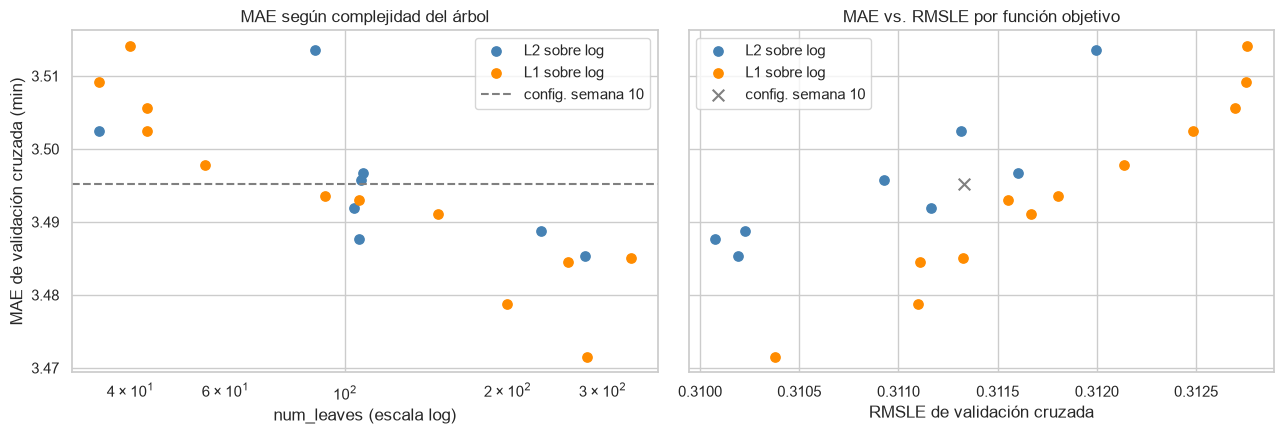

In [8]:
colores = {'regression': 'steelblue', 'regression_l1': 'darkorange'}
etiquetas = {'regression': 'L2 sobre log', 'regression_l1': 'L1 sobre log'}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for objetivo, grupo in busqueda.groupby('objective'):
    axes[0].scatter(grupo['num_leaves'], grupo['cv_MAE'], color=colores[objetivo], label=etiquetas[objetivo], s=45)
    axes[1].scatter(grupo['cv_RMSLE'], grupo['cv_MAE'], color=colores[objetivo], label=etiquetas[objetivo], s=45)
axes[0].axhline(r_ref['cv_MAE'], color='gray', linestyle='--', label='config. semana 10')
axes[1].scatter(r_ref['cv_RMSLE'], r_ref['cv_MAE'], color='gray', marker='x', s=70, label='config. semana 10')
axes[0].set_xscale('log')
axes[0].set_xlabel('num_leaves (escala log)')
axes[0].set_ylabel('MAE de validación cruzada (min)')
axes[0].set_title('MAE según complejidad del árbol')
axes[1].set_xlabel('RMSLE de validación cruzada')
axes[1].set_title('MAE vs. RMSLE por función objetivo')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.savefig('../reports/figures/07_busqueda_hiperparametros.png', dpi=150)
plt.show()

## 6. Refinamiento: learning rate más bajo

Tomamos la mejor configuración de la búsqueda y la reevaluamos con `learning_rate = 0.05`. El early stopping compensa con más árboles; se conserva la versión con menor MAE de validación cruzada.

In [9]:
PARAMS = ['objective', 'learning_rate', 'num_leaves', 'min_child_samples', 'subsample',
          'colsample_bytree', 'reg_alpha', 'reg_lambda']

def a_params(fila):
    return {k: (v.item() if hasattr(v, 'item') else v) for k, v in fila[PARAMS].items()}

mejor = busqueda.iloc[0]
params_mejor = a_params(mejor)
params_lento = {**params_mejor, 'learning_rate': 0.05}

r_lento = tuning.evaluar_config(params_lento, folds, excluir=EXCLUIR, max_arboles=6000, paciencia=PACIENCIA)
print(f"lr = {LR_BUSQUEDA}: cv_MAE = {mejor['cv_MAE']:.4f} | árboles = {mejor['arboles_por_fold']}")
print(f"lr = 0.05: cv_MAE = {r_lento['cv_MAE']:.4f} | árboles = {r_lento['arboles_por_fold']} | {r_lento['segundos']:.0f} s")

if r_lento['cv_MAE'] < mejor['cv_MAE']:
    params_final, r_final = params_lento, r_lento
else:
    params_final, r_final = params_mejor, mejor.to_dict()
arboles_final = int(round(np.mean(r_final['arboles_por_fold'])))
print(f"\nConfiguración elegida: {params_final} con {arboles_final} árboles")

lr = 0.2: cv_MAE = 3.4715 | árboles = [234, 312, 365]
lr = 0.05: cv_MAE = 3.4488 | árboles = [802, 1263, 1592] | 413 s

Configuración elegida: {'objective': 'regression_l1', 'learning_rate': 0.05, 'num_leaves': 281, 'min_child_samples': 30, 'subsample': 0.78, 'colsample_bytree': 0.685, 'reg_alpha': 5.094, 'reg_lambda': 0.3762} con 1219 árboles


## 7. Comparación final sobre mayo

Mayo no participó en la búsqueda. Reajustamos el preprocesador con todo enero-abril y comparamos tres modelos:

- **H**: LightGBM con los hiperparámetros de la semana 10 (reproduce el notebook 03).
- **I**: mejor configuración con objetivo L2 de la búsqueda. Sirve para separar cuánto aporta ajustar los hiperparámetros y cuánto cambiar la función objetivo.
- **J**: configuración elegida en la sección 6.

Los modelos I y J usan el número de árboles promedio de sus folds, sin early stopping sobre mayo.

In [10]:
X_tr, y_tr_log = preparar_xy(train, usar_log_target=True)
X_val, _ = preparar_xy(val)
y_val = val['trip_duration_min'].to_numpy(dtype=float)

prep = construir_preprocesador(escalar_numericas=False)
Xt_tr = prep.fit_transform(X_tr, y_tr_log).astype(np.float32)
Xt_val = prep.transform(X_val).astype(np.float32)
nombres = prep.named_steps['codificador'].get_feature_names_out()
cols = tuning.columnas_a_usar(nombres, EXCLUIR)
todas = tuning.columnas_a_usar(nombres)

resultados = []

def entrenar_y_evaluar(nombre, params, n_arboles, columnas):
    t0 = time.time()
    modelo = lgb.LGBMRegressor(n_estimators=n_arboles, **tuning.PARAMS_FIJOS, **params)
    modelo.fit(Xt_tr[:, columnas], y_tr_log)
    segundos = round(time.time() - t0, 1)
    m = tuning.metricas(y_val, np.expm1(modelo.predict(Xt_val[:, columnas])))
    print(f"{nombre:<46} MAE = {m['MAE']:6.3f} min | RMSLE = {m['RMSLE']:.4f} | {n_arboles} árboles | {segundos} s")
    resultados.append({'modelo': nombre, **m, 'arboles': n_arboles, 'segundos_entrenamiento': segundos})
    return modelo

# H: configuración y features del notebook 03 (500 árboles fijos, con pickup_month)
entrenar_y_evaluar("H: LightGBM (semana 10)", tuning.PARAMS_SEMANA_10, 500, todas)

mejor_l2 = busqueda[busqueda['objective'] == 'regression'].iloc[0]
entrenar_y_evaluar("I: LightGBM ajustado, objetivo L2", a_params(mejor_l2),
                   int(round(np.mean(mejor_l2['arboles_por_fold']))), cols)

modelo_final = entrenar_y_evaluar("J: LightGBM ajustado (configuración elegida)", params_final, arboles_final, cols)

H: LightGBM (semana 10)                        MAE =  4.072 min | RMSLE = 0.3206 | 500 árboles | 27.0 s


I: LightGBM ajustado, objetivo L2              MAE =  4.054 min | RMSLE = 0.3199 | 218 árboles | 21.4 s


J: LightGBM ajustado (configuración elegida)   MAE =  4.015 min | RMSLE = 0.3183 | 1219 árboles | 147.9 s


In [11]:
tabla = pd.DataFrame(resultados)
mae_h = tabla.loc[0, 'MAE']
tabla['mejora_vs_H_%'] = ((mae_h - tabla['MAE']) / mae_h * 100).round(1)

assert tabla['MAE'].min() >= 2, "MAE sospechosamente bajo: auditar features por leakage"
print("OK: ningún modelo baja de 2 min de MAE (chequeo de sanidad de leakage)")
tabla

OK: ningún modelo baja de 2 min de MAE (chequeo de sanidad de leakage)


,modelo,MAE,RMSLE,arboles,segundos_entrenamiento,mejora_vs_H_%
0,H: LightGBM (semana 10),4.072227,0.320563,500,27.0,0.0
1,"I: LightGBM ajustado, objetivo L2",4.053586,0.319852,218,21.4,0.5
2,J: LightGBM ajustado (configuración elegida),4.015426,0.318324,1219,147.9,1.4


## 8. Guardado de resultados
- `outputs/metrics_tuning.json`: métricas sobre mayo de los modelos H, I y J.
- `outputs/mejores_hiperparametros.json`: configuración elegida, para reentrenar en la semana 12 sin repetir la búsqueda.
- `reports/busqueda_hiperparametros.csv`: todas las configuraciones evaluadas con su puntaje de validación cruzada.

In [12]:
Path('../outputs').mkdir(exist_ok=True)

with open('../outputs/metrics_tuning.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)

elegida = {
    'modelo': 'LightGBM',
    'params': params_final,
    'n_estimators': arboles_final,
    'params_fijos': tuning.PARAMS_FIJOS,
    'target': 'log1p(trip_duration_min)',
    'features_excluidas': list(EXCLUIR),
    'cv_MAE': r_final['cv_MAE'],
    'cv_RMSLE': r_final['cv_RMSLE'],
    'val_mayo': {k: resultados[-1][k] for k in ('MAE', 'RMSLE')},
    'validacion': 'TimeSeriesSplit(n_splits=3) sobre enero-abril, SAMPLE_FRAC=0.20, SEED=42',
}
with open('../outputs/mejores_hiperparametros.json', 'w', encoding='utf-8') as f:
    json.dump(elegida, f, indent=2, ensure_ascii=False)

busqueda.to_csv('../reports/busqueda_hiperparametros.csv', index=False)
print("Guardado: outputs/metrics_tuning.json, outputs/mejores_hiperparametros.json, reports/busqueda_hiperparametros.csv")

Guardado: outputs/metrics_tuning.json, outputs/mejores_hiperparametros.json, reports/busqueda_hiperparametros.csv


## 9. Lectura de resultados

Resultados sobre validación (mayo), mismo split y muestreo que los notebooks 02 y 03:

| Modelo | MAE (min) | RMSLE | Árboles | MAE en validación cruzada |
|---|---|---|---|---|
| H. LightGBM, semana 10 | 4.07 | 0.3206 | 500 | 3.50 |
| I. LightGBM ajustado, objetivo L2 | 4.05 | 0.3199 | 218 | 3.49 |
| **J. LightGBM ajustado, objetivo L1** | **4.02** | **0.3183** | 1219 | 3.45 |

**La búsqueda mejora poco: de 4.07 a 4.02 min de MAE en mayo (−1.4 %).** El modelo J también mejora el RMSLE (0.3206 a 0.3183). La configuración elegida usa árboles más grandes (`num_leaves=281`), objetivo L1 sobre `log1p(duración)`, `learning_rate=0.05` y 1219 árboles; queda en `outputs/mejores_hiperparametros.json`.

**Los hiperparámetros no son el cuello de botella.** Las 20 configuraciones quedaron entre 3.47 y 3.51 min de MAE en validación cruzada, un rango de 0.04 min, y la configuración de la semana 10 (3.50) ya estaba dentro de ese rango. Lo poco que se gana viene de tres fuentes:
- **Árboles más grandes**: el MAE baja al subir `num_leaves` (figura, panel izquierdo); cinco de las seis peores configuraciones tienen menos de 60 hojas.
- **Objetivo L1**: las cuatro mejores configuraciones usan L1, que apunta a la mediana y por eso favorece el MAE. A cambio, las mejores en RMSLE son las de objetivo L2 (figura, panel derecho). En mayo, pasar de la mejor L2 (I) a la elegida (J) baja el MAE de 4.05 a 4.02, aunque J además usa un learning rate más bajo, así que los dos efectos no quedan separados.
- **Learning rate más bajo**: bajar de 0.2 a 0.05 mejoró el MAE de validación cruzada de 3.47 a 3.45, a costa de 4 veces más árboles.

**`pickup_month` se queda.** Quitarla no mejoró la validación cruzada (3.504 sin la feature contra 3.495 con ella). La diferencia es menor que la variación entre folds (0.09 min), así que la feature no ayuda ni estorba de forma medible; se conserva por la regla fijada en la sección 4.

**Mayo es más difícil que los folds.** El MAE en validación cruzada (3.45 a 3.50) es unos 0.57 min menor que el de mayo (4.02 a 4.07) para los tres modelos. Parte se explica porque el early stopping hace optimista el puntaje de cada fold, pero la tendencia ya aparece dentro de entrenamiento: con la configuración de la semana 10, el MAE por fold sube de 3.39 (febrero) a 3.49 (marzo) y 3.60 (abril). Es la deriva temporal anticipada en la sección 12 del proposal, y por eso el error esperable en junio se parece más al de mayo que al de la validación cruzada.

**Limitaciones.**
- Son 20 configuraciones sobre una muestra del 20 % de cada mes; una búsqueda más larga podría encontrar algo mejor, pero el rango tan estrecho sugiere que la ganancia sería marginal.
- El número de árboles de los modelos I y J es el promedio de folds que entrenan con menos datos que enero-abril completo, así que puede quedar algo corto.
- Mayo se usó para comparar tres modelos, por lo que su MAE ya no es una estimación del todo limpia. La estimación final es la de junio.

**Siguientes pasos (semana 12):** reentrenar la configuración elegida y evaluarla una sola vez sobre junio, con análisis de errores por zona, hora y distancia. Dado que ajustar hiperparámetros rinde poco, las mejoras futuras tendrían que venir de las features (la distancia estimada concentra ~86 % de la ganancia, notebook 03) y no de más búsqueda.

Las métricas de este notebook están en `outputs/metrics_tuning.json` y todas las configuraciones evaluadas en `reports/busqueda_hiperparametros.csv`.